# Task 3: Sales Prediction Using Machine Learning

## Internship
WeIntern Pvt. Ltd. – Data Science Internship

## Project Overview
This project focuses on predicting daily retail sales using machine learning regression models. Historical transaction data will be analyzed to identify sales patterns and generate predictions.

## Dataset
Retail Store Sales – Cleaned Dataset (Prepared in Task 1).

## Objectives
- Prepare data for sales prediction.
- Perform feature selection and feature engineering.
- Split data into training and testing sets.
- Build at least two regression models.
- Evaluate models using RMSE, MAE, and R².
- Perform hyperparameter tuning.
- Compare actual and predicted sales.
- Identify important features.

## Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set visualization style
sns.set_theme(style="whitegrid")

# Load cleaned retail dataset
file_path = "../datasets/processed/cleaned_retail_store_sales.csv"
df = pd.read_csv(file_path)

# Convert transaction date
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (12575, 11)


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    12575 non-null  str           
 1   customer_id       12575 non-null  str           
 2   category          12575 non-null  str           
 3   item              12575 non-null  str           
 4   price_per_unit    12575 non-null  float64       
 5   quantity          11971 non-null  float64       
 6   total_spent       11971 non-null  float64       
 7   payment_method    12575 non-null  str           
 8   location          12575 non-null  str           
 9   transaction_date  12575 non-null  datetime64[us]
 10  discount_applied  12575 non-null  str           
dtypes: datetime64[us](1), float64(3), str(7)
memory usage: 1.1 MB

Missing Values:


transaction_id        0
customer_id           0
category              0
item                  0
price_per_unit        0
quantity            604
total_spent         604
payment_method        0
location              0
transaction_date      0
discount_applied      0
dtype: int64

## 1. Data Preparation and Feature Engineering

The transaction-level retail dataset is converted into daily sales data. Transactions with missing sales values are excluded from revenue aggregation. Date-based features are created for machine learning.

In [12]:
# Keep records with valid sales values
sales_df = df.dropna(
    subset=["total_spent"]
).copy()

# Aggregate transaction sales by date
daily_sales = (
    sales_df.groupby("transaction_date")
    .agg(
        daily_sales=("total_spent", "sum"),
        total_transactions=("transaction_id", "count"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

# Sort data chronologically
daily_sales = daily_sales.sort_values(
    "transaction_date"
).reset_index(drop=True)

# Create calendar-based features
daily_sales["day"] = daily_sales["transaction_date"].dt.day
daily_sales["month"] = daily_sales["transaction_date"].dt.month
daily_sales["year"] = daily_sales["transaction_date"].dt.year
daily_sales["day_of_week"] = daily_sales["transaction_date"].dt.day_of_week

# Display prepared dataset
print("Daily Sales Dataset Created!")
print("Shape:", daily_sales.shape)

display(daily_sales.head(10))

print("\nDate Range:")
print(daily_sales["transaction_date"].min())
print(daily_sales["transaction_date"].max())

Daily Sales Dataset Created!
Shape: (1114, 8)


,transaction_date,daily_sales,total_transactions,total_quantity,day,month,year,day_of_week
0,2022-01-01,1642.5,11,69.0,1,1,2022,5
1,2022-01-02,1135.5,8,39.0,2,1,2022,6
2,2022-01-03,823.0,8,44.0,3,1,2022,0
3,2022-01-04,1117.5,8,42.0,4,1,2022,1
4,2022-01-05,2227.5,13,81.0,5,1,2022,2
5,2022-01-06,763.5,8,36.0,6,1,2022,3
6,2022-01-07,1372.5,12,72.0,7,1,2022,4
7,2022-01-08,1496.5,14,68.0,8,1,2022,5
8,2022-01-09,1866.0,14,78.0,9,1,2022,6
9,2022-01-10,1340.5,11,59.0,10,1,2022,0



Date Range:
2022-01-01 00:00:00
2025-01-18 00:00:00


## 2. Feature Engineering

Lag features and rolling averages are created using historical daily sales. These features help machine learning models learn from previous sales patterns while avoiding future data leakage.

In [3]:
# Create historical sales features
daily_sales["lag_1"] = daily_sales["daily_sales"].shift(1)
daily_sales["lag_7"] = daily_sales["daily_sales"].shift(7)
daily_sales["lag_30"] = daily_sales["daily_sales"].shift(30)

# Create rolling average using previous 7 days
daily_sales["rolling_mean_7"] = (
    daily_sales["daily_sales"].shift(1).rolling(window=7).mean()
)

# Remove rows with missing lag values
model_df = daily_sales.dropna().copy()

# Display engineered features
print("Feature Engineering Completed!")
print("Original Daily Records:", len(daily_sales))
print("Records After Feature Engineering:", len(model_df))

display(model_df.head())

print("\nAvailable Features:")
print(model_df.columns.tolist())

Feature Engineering Completed!
Original Daily Records: 1114
Records After Feature Engineering: 1084


,transaction_date,daily_sales,total_transactions,total_quantity,day,month,year,day_of_week,lag_1,lag_7,lag_30,rolling_mean_7
30,2022-01-31,2310.5,12,88.0,31,1,2022,0,1532.0,1544.0,1642.5,1701.785714
31,2022-02-01,1413.5,12,67.0,1,2,2022,1,2310.5,1174.5,1135.5,1811.285714
32,2022-02-02,2251.5,17,93.0,2,2,2022,2,1413.5,2808.0,823.0,1845.428571
33,2022-02-03,1137.5,6,34.0,3,2,2022,3,2251.5,1135.0,1117.5,1765.928571
34,2022-02-04,1563.5,10,70.0,4,2,2022,4,1137.5,2063.0,2227.5,1766.285714



Available Features:
['transaction_date', 'daily_sales', 'total_transactions', 'total_quantity', 'day', 'month', 'year', 'day_of_week', 'lag_1', 'lag_7', 'lag_30', 'rolling_mean_7']


## 3. Feature Selection and Train-Test Split

Historical sales features and calendar-based variables are selected for prediction. The dataset is divided chronologically into 80% training data and 20% testing data to preserve the time-series order and prevent data leakage.

In [4]:
# Select input features
features = [
    "day",
    "month",
    "year",
    "day_of_week",
    "lag_1",
    "lag_7",
    "lag_30",
    "rolling_mean_7"
]

# Define features and target
X = model_df[features]
y = model_df["daily_sales"]

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("TRAIN-TEST SPLIT COMPLETED")
print("-" * 40)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Date Range:")
print(model_df["transaction_date"].iloc[0])
print("to", model_df["transaction_date"].iloc[split_index - 1])

print("\nTesting Date Range:")
print(model_df["transaction_date"].iloc[split_index])
print("to", model_df["transaction_date"].iloc[-1])

print("\nSelected Features:")
print(features)

TRAIN-TEST SPLIT COMPLETED
----------------------------------------
Training Records: 867
Testing Records: 217

Training Date Range:
2022-01-31 00:00:00
to 2024-06-15 00:00:00

Testing Date Range:
2024-06-16 00:00:00
to 2025-01-18 00:00:00

Selected Features:
['day', 'month', 'year', 'day_of_week', 'lag_1', 'lag_7', 'lag_30', 'rolling_mean_7']


In [5]:
date_gaps = daily_sales["transaction_date"].sort_values().diff().dt.days

print("Total Date Records:", len(daily_sales))

print("\nDays Between Records:")
display(date_gaps.value_counts().sort_index().head(15))

print("\nGaps Greater Than 1 Day:", (date_gaps > 1).sum())
print("Maximum Gap:", date_gaps.max())

Total Date Records: 1114

Days Between Records:


transaction_date
1.0    1113
Name: count, dtype: int64


Gaps Greater Than 1 Day: 0
Maximum Gap: 1.0


## 4. Model Training

Two regression models are trained to predict daily retail sales:

1. Linear Regression – Baseline model.
2. Random Forest Regressor – Ensemble model that can learn complex patterns.

Both models are trained using the training dataset.

In [6]:
# Initialize models
linear_model = LinearRegression()

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

# Train Linear Regression
linear_model.fit(X_train, y_train)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Both Models Trained Successfully!")

Both Models Trained Successfully!


## 5. Model Evaluation

The trained models are evaluated using three performance metrics:

- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² Score (Coefficient of Determination)

Lower MAE and RMSE indicate better prediction accuracy, while a higher R² score indicates a better model fit.

In [7]:
# Generate predictions
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
model_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_results.round(2))

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,369.01,477.02,-0.04
1,Random Forest,380.75,480.47,-0.06


## 6. Hyperparameter Tuning

Random Forest hyperparameters are optimized using RandomizedSearchCV and TimeSeriesSplit. TimeSeriesSplit preserves chronological order during cross-validation and helps avoid future data leakage.

In [8]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 1.0]
}

# Time-series cross-validation
time_split = TimeSeriesSplit(n_splits=3)

# Initialize Random Forest
rf_tuning_model = RandomForestRegressor(random_state=42)

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=param_grid,
    n_iter=10,
    cv=time_split,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

# Fit using training data only
random_search.fit(X_train, y_train)

# Best model
best_rf_model = random_search.best_estimator_

print("HYPERPARAMETER TUNING COMPLETED!")
print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-random_search.best_score_, 2))

HYPERPARAMETER TUNING COMPLETED!

Best Parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20}

Best Cross-Validation RMSE:
572.88


## 7. Tuned Model Evaluation

The best Random Forest model obtained through hyperparameter tuning is evaluated on the test dataset. Its performance is compared with the baseline models using MAE, RMSE, and R².

In [9]:
# Predict using tuned Random Forest model
tuned_predictions = best_rf_model.predict(X_test)

# Calculate tuned model metrics
tuned_results = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "MAE": [mean_absolute_error(y_test, tuned_predictions)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, tuned_predictions))],
    "R2 Score": [r2_score(y_test, tuned_predictions)]
})

# Combine all model results
final_model_results = pd.concat(
    [model_results, tuned_results],
    ignore_index=True
)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(final_model_results.round(2))

FINAL MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,369.01,477.02,-0.04
1,Random Forest,380.75,480.47,-0.06
2,Tuned Random Forest,372.61,473.49,-0.03


## 8. Actual vs Predicted Sales

The actual daily sales values are compared with the predictions generated by the tuned Random Forest model on the test dataset.

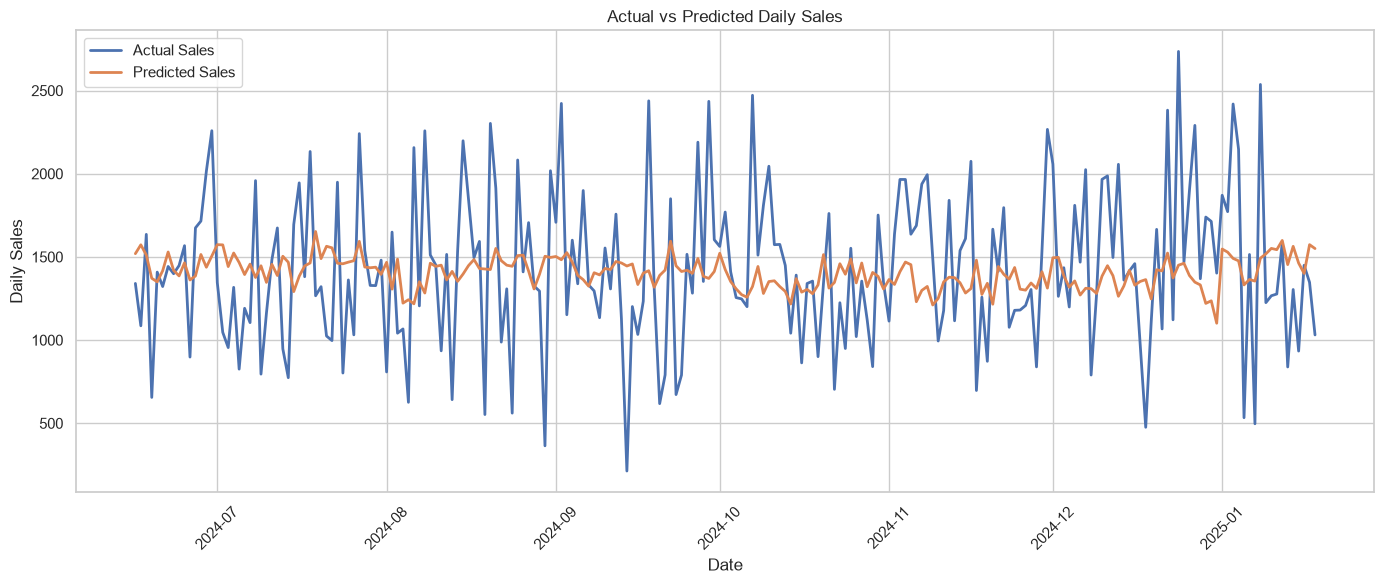

In [10]:
# Get test dates
test_dates = model_df["transaction_date"].iloc[split_index:]

# Plot actual vs predicted sales
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test.values,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    test_dates,
    tuned_predictions,
    label="Predicted Sales",
    linewidth=2
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis

Feature importance is analyzed using the tuned Random Forest model to identify which input variables contribute most to sales predictions.

FEATURE IMPORTANCE


,Feature,Importance
5,lag_7,0.1734
7,rolling_mean_7,0.1733
6,lag_30,0.1623
4,lag_1,0.1532
0,day,0.1248
1,month,0.1082
3,day_of_week,0.0682
2,year,0.0367


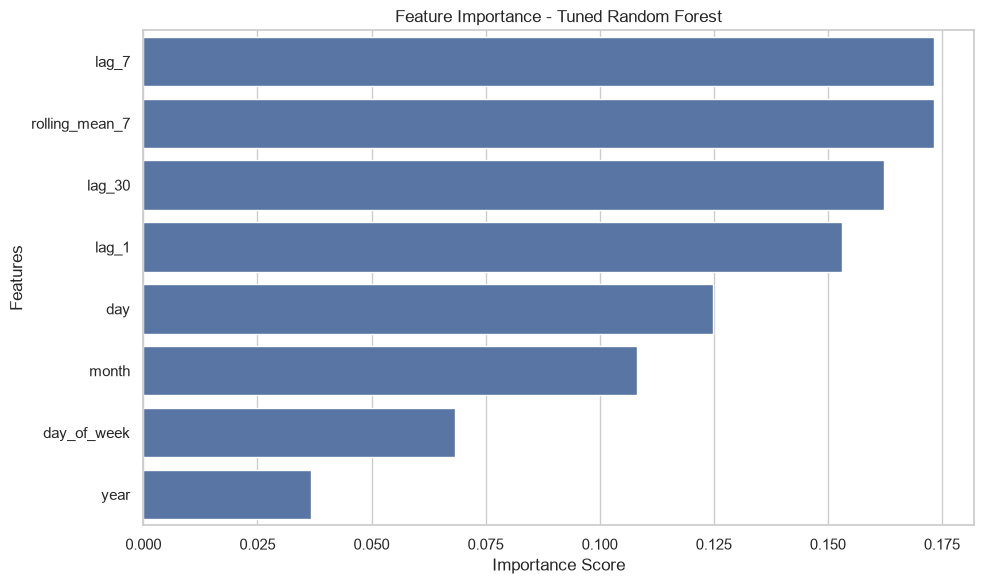

In [11]:
# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
display(feature_importance.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## 10. Key Findings and Business Insights

1. The Tuned Random Forest model achieved the lowest RMSE of 473.49 among the three evaluated models.
2. Historical sales features, particularly lag_7 and rolling_mean_7, were the most important features in the tuned Random Forest model.
3. Calendar features such as day and month also contributed to sales predictions.
4. The actual vs predicted chart shows that the model captures general sales levels but struggles to predict sudden sales peaks and drops.
5. All models produced negative R² scores, indicating that their predictive performance needs improvement.

### Business Recommendations

- Monitor historical weekly sales patterns to support inventory planning.
- Use monthly and daily sales trends to plan promotional activities.
- Collect additional information such as holidays, festivals, discounts, and product-level demand to improve future predictions.

## 11. Model Limitations

- The dataset contains historical retail transactions and is not specifically designed for sales forecasting.
- Only 1,114 daily records were available for modeling.
- Missing sales values were excluded during daily sales aggregation.
- All evaluated models produced negative R² scores, indicating limited predictive performance.
- The model may not capture unexpected demand changes, festivals, promotions, or external market conditions.

## 12. Conclusion

This project demonstrated the complete machine learning workflow for retail sales prediction, including data preparation, feature engineering, chronological train-test splitting, regression model training, evaluation, and hyperparameter tuning.

Three models were evaluated: Linear Regression, Random Forest, and Tuned Random Forest. The Tuned Random Forest achieved the lowest RMSE of 473.49 and was selected as the best-performing model among the evaluated models.

However, the negative R² score indicates that further improvements and additional relevant data are required to develop a reliable sales prediction system.